# Bài thực hành: Ước lượng điểm và khoảng tin cậy
**Bộ dữ liệu:** File dữ liệu `Students_data.csv` (105 sinh viên ngành Toán, đã được chỉnh sửa để bảo mật thông tin) được lấy từ Kaggle (https://www.kaggle.com/datasets/erqizhou/students-data-analysis)

**Công cụ:** Python

### Cấu trúc bài
| Phần | Nội dung |
|---|---|
| 1 | Giới thiệu và phân loại biến |
| 2 | Các hàm tính khoảng tin cậy tự viết từ công thức |
| 3 | (a) CI 95% cho kỳ vọng μ của `GPA` |
| 4 | (b) CI 95% cho phương sai σ² của `Calculus1` |
| 5 | (c) CI 95% cho tỷ lệ p sinh viên nữ |
| 6 | (d) CI 95% cho hiệu kỳ vọng GPA giữa nam và nữ |
| 7 | Đối chiếu với hàm có sẵn, tổng hợp và hạn chế |

## 1. Giới thiệu bộ dữ liệu
### 1.1 Nạp dữ liệu

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams['figure.figsize'] = (6, 3.6)

CONF = 0.95
ALPHA = 1 - CONF

candidates = ['Students data.csv'] + glob.glob('/kaggle/input/**/Students_data.csv', recursive=True)
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError('Không tìm thấy Students_data.csv.')

df = pd.read_csv(path)
print('Đọc từ:', path)
print('Kích thước (số dòng, số cột):', df.shape)
df.head()

Đọc từ: Students data.csv
Kích thước (số dòng, số cột): (105, 17)


,ID,class,gender,race,GPA,Algebra,Calculus1,Calculus2,Statistics,Probability,Measure,Functional_analysis,from1,from2,from3,from4,y
0,1141,A,male,1,73.4700,64,81,87,60,74,71,60,A,A,A,3,0
1,1142,A,female,1,71.2200,57,50,51,51,55,62,61,B,A,A,2,0
2,1143,A,female,2,74.5600,47,48,71,60,61,68,64,C,A,A,0,1
3,1144,A,female,1,72.8900,46,72,38,60,29,54,51,D,A,A,0,0
4,1145,A,female,1,70.1100,49,45,63,60,66,66,61,E,A,A,0,0


### 1.2 Kiểm tra chất lượng dữ liệu và ép kiểu
Một số cột được lưu bằng số nhưng bản chất là biến định tính: `race` (mã chủng tộc), `from4` (chỉ báo gia cảnh), `y` (kết quả 0/1/2). Nếu không ép kiểu, rất dễ lỡ tính trung bình trên các cột này.

In [2]:
print('Giá trị thiếu theo cột:'); print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else 'Không có giá trị thiếu')
print('ID bị trùng:', df['ID'].duplicated().sum())

for c in ['race', 'from4', 'y']:
    df[c] = df[c].astype('category')

df.info()

Giá trị thiếu theo cột:
Không có giá trị thiếu
ID bị trùng: 0
<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   ID                   105 non-null    int64   
 1   class                105 non-null    str     
 2   gender               105 non-null    str     
 3   race                 105 non-null    category
 4   GPA                  105 non-null    float64 
 5   Algebra              105 non-null    int64   
 6   Calculus1            105 non-null    int64   
 7   Calculus2            105 non-null    int64   
 8   Statistics           105 non-null    int64   
 9   Probability          105 non-null    int64   
 10  Measure              105 non-null    int64   
 11  Functional_analysis  105 non-null    int64   
 12  from1                105 non-null    str     
 13  from2                105 non-null    str     
 14  from3                10

### 1.3 Bối cảnh và phân loại biến
**Bối cảnh:** dữ liệu gồm 105 sinh viên của một chương trình Toán (các môn Đại số, Giải tích, Xác suất, Thống kê, Độ đo, Giải tích hàm). Mỗi dòng là một sinh viên, kèm GPA, điểm các môn, thông tin xuất thân và kết quả nộp hồ sơ cao học (`y`). Dữ liệu đã được chỉnh sửa nhẹ để bảo vệ thông tin cá nhân, nên kết quả bên dưới dùng để minh họa phương pháp, không nhằm kết luận về thực tế.

| Biến | Loại | Ý nghĩa |
|---|---|---|
| `ID` | định danh | mã sinh viên (không phân tích) |
| `class` | định tính (danh nghĩa) | lớp A hoặc B |
| `gender` | định tính (nhị phân) | `male` / `female` |
| `race` | định tính (danh nghĩa) | mã chủng tộc (đã ẩn danh) |
| `GPA` | định lượng (liên tục) | điểm trung bình, thang 100 |
| `Algebra`, `Calculus1`, `Calculus2`, `Statistics`, `Probability`, `Measure`, `Functional_analysis` | định lượng (rời rạc, điểm nguyên 0–100) | điểm từng môn |
| `from1` | định tính (danh nghĩa, 28 giá trị) | quê quán (đã ẩn danh) |
| `from2` | định tính (nhị phân) | chỉ báo thiên hướng thích toán (đã ẩn danh) |
| `from3` | định tính (danh nghĩa) | cách thức vào trường đại học |
| `from4` | định tính (thứ bậc) | chỉ báo gia cảnh: 0 khá giả hơn, số lớn nghèo hơn |
| `y` | định tính (danh nghĩa) | 0: chưa nộp được cao học; 1: thành công trong nước; 2: thành công nước ngoài |

In [3]:
quant = ['GPA', 'Algebra', 'Calculus1', 'Calculus2', 'Statistics', 'Probability', 'Measure', 'Functional_analysis']
display(df[quant].describe().T)

for c in ['class', 'gender', 'y']:
    print(f'\n--- {c} ---')
    print(df[c].value_counts().sort_index())

,count,mean,std,min,25%,50%,75%,max
GPA,105.0000,82.9570,6.0532,63.4900,79.3400,84.1100,87.3000,93.7100
Algebra,105.0000,76.0571,11.7226,46.0000,67.0000,76.0000,84.0000,98.0000
Calculus1,105.0000,71.9619,12.1970,38.0000,64.0000,73.0000,80.0000,100.0000
Calculus2,105.0000,78.9429,14.9973,17.0000,71.0000,83.0000,91.0000,99.0000
Statistics,105.0000,85.1333,10.2695,51.0000,80.0000,87.0000,92.0000,100.0000
Probability,105.0000,83.8762,10.5144,29.0000,79.0000,85.0000,92.0000,97.0000
Measure,105.0000,80.7619,10.2961,54.0000,74.0000,81.0000,89.0000,100.0000
Functional_analysis,105.0000,75.3238,13.0033,9.0000,67.0000,76.0000,85.0000,100.0000



--- class ---
class
A    76
B    29
Name: count, dtype: int64

--- gender ---
gender
female    68
male      37
Name: count, dtype: int64

--- y ---
y
0    55
1    25
2    25
Name: count, dtype: int64


### 1.4 Giả định về tổng thể
Ta coi 105 sinh viên là một mẫu ngẫu nhiên đại diện cho tổng thể sinh viên cùng chương trình. Đây là giả định cần nêu rõ, vì dữ liệu thực tế là toàn bộ một nhóm sinh viên và không được ghi nhận cách chọn mẫu. Mọi khoảng tin cậy bên dưới đều dựa trên giả định này.

## 2. Các hàm tính khoảng tin cậy

Mỗi hàm bên dưới làm đúng các bước: tính thống kê mẫu → tra giá trị tới hạn → tính sai số biên → ghép thành khoảng. `scipy.stats` chỉ được dùng cho bước tra giá trị tới hạn (`ppf` là hàm ngược của hàm phân phối tích lũy, tức là phân vị).

Quy ước: độ tin cậy $1-\alpha = 0.95$ nên $\alpha = 0.05$ và mỗi đuôi là $\alpha/2 = 0.025$.

**Lưu ý:**
- Độ lệch chuẩn mẫu phải dùng `ddof=1` (chia cho $n-1$), mặc định của numpy là `ddof=0`.
- `ppf(1 - α/2)` cho giá trị tới hạn phía phải, ví dụ `stats.t.ppf(0.975, df)` ≈ 1.98 khi bậc tự do lớn.

In [4]:
def ci_mean(x, conf=0.95):
    x = np.asarray(x, dtype=float)
    n = len(x)
    x_bar = x.mean()
    s = x.std(ddof=1)
    t_crit = stats.t.ppf(1 - (1 - conf) / 2, df=n - 1)
    margin = t_crit * s / np.sqrt(n)
    return dict(n=n, x_bar=x_bar, s=s, t_crit=t_crit, margin=margin,
                lower=x_bar - margin, upper=x_bar + margin)


def ci_var(x, conf=0.95):
    x = np.asarray(x, dtype=float)
    n = len(x)
    s2 = x.var(ddof=1)
    a = 1 - conf
    chi_right = stats.chi2.ppf(1 - a / 2, df=n - 1)
    chi_left = stats.chi2.ppf(a / 2, df=n - 1)
    lower = (n - 1) * s2 / chi_right
    upper = (n - 1) * s2 / chi_left
    return dict(n=n, s2=s2, chi_left=chi_left, chi_right=chi_right, lower=lower, upper=upper,
                sd_lower=np.sqrt(lower), sd_upper=np.sqrt(upper))


def ci_prop(successes, n, conf=0.95):
    p_hat = successes / n
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    margin = z * se
    return dict(n=n, successes=successes, p_hat=p_hat, z=z, se=se, margin=margin,
                lower=p_hat - margin, upper=p_hat + margin)


def ci_diff_welch(x1, x2, conf=0.95):
    x1, x2 = np.asarray(x1, float), np.asarray(x2, float)
    n1, n2 = len(x1), len(x2)
    v1, v2 = x1.var(ddof=1), x2.var(ddof=1)
    se = np.sqrt(v1 / n1 + v2 / n2)
    df_w = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    t_crit = stats.t.ppf(1 - (1 - conf) / 2, df=df_w)
    diff = x1.mean() - x2.mean()
    margin = t_crit * se
    return dict(n1=n1, n2=n2, mean1=x1.mean(), mean2=x2.mean(), diff=diff, se=se, df=df_w,
                t_crit=t_crit, margin=margin, lower=diff - margin, upper=diff + margin)


def ci_diff_pooled(x1, x2, conf=0.95):
    x1, x2 = np.asarray(x1, float), np.asarray(x2, float)
    n1, n2 = len(x1), len(x2)
    v1, v2 = x1.var(ddof=1), x2.var(ddof=1)
    sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
    se = np.sqrt(sp2 * (1 / n1 + 1 / n2))
    df_p = n1 + n2 - 2
    t_crit = stats.t.ppf(1 - (1 - conf) / 2, df=df_p)
    diff = x1.mean() - x2.mean()
    margin = t_crit * se
    return dict(n1=n1, n2=n2, mean1=x1.mean(), mean2=x2.mean(), diff=diff, sp2=sp2, se=se, df=df_p,
                t_crit=t_crit, margin=margin, lower=diff - margin, upper=diff + margin)


def show(d, title=''):
    print(title)
    display(pd.Series(d, name='giá trị').to_frame())

## 3. Câu (a): Khoảng tin cậy 95% cho kỳ vọng μ của `GPA`

**Công thức** (chưa biết σ² tổng thể):
$$\bar{x} \;\pm\; t_{n-1,\;\alpha/2}\cdot\frac{s}{\sqrt{n}}$$
trong đó $\bar x$ là trung bình mẫu, $s$ là độ lệch chuẩn mẫu ($\text{ddof}=1$), $n$ là cỡ mẫu và $t_{n-1,\alpha/2}$ là giá trị tới hạn của phân phối Student bậc tự do $n-1$.

**Điều kiện áp dụng:**
1. Mẫu ngẫu nhiên, các quan sát độc lập (giả định ở mục 1.4).
2. Tổng thể xấp xỉ chuẩn, hoặc $n$ đủ lớn (thường $n \ge 30$) để Định lý giới hạn trung tâm (CLT) làm trung bình mẫu xấp xỉ chuẩn.

Ta kiểm tra điều kiện 2 bằng biểu đồ và độ lệch.

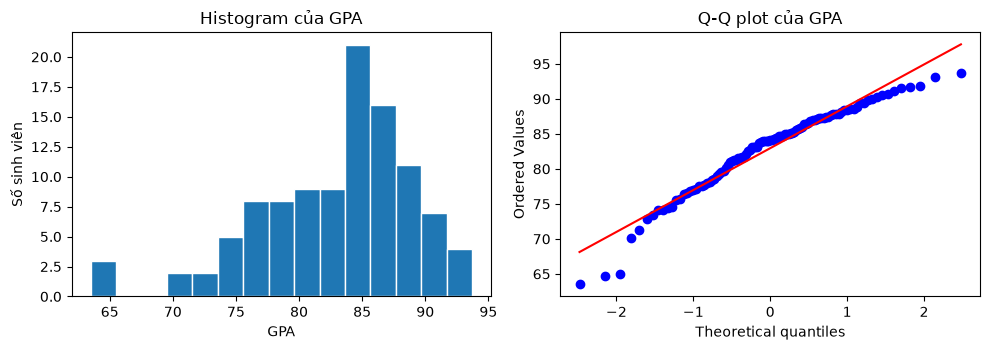

n = 105   độ lệch (skewness) = -0.912   Shapiro-Wilk p = 0.0004342


In [5]:
gpa = df['GPA']

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(gpa, bins=15, edgecolor='white')
ax[0].set_title('Histogram của GPA'); ax[0].set_xlabel('GPA'); ax[0].set_ylabel('Số sinh viên')
stats.probplot(gpa, plot=ax[1]); ax[1].set_title('Q-Q plot của GPA')
plt.tight_layout(); plt.show()

print(f'n = {len(gpa)}   độ lệch (skewness) = {gpa.skew():.3f}   Shapiro-Wilk p = {stats.shapiro(gpa).pvalue:.4g}')

**Đọc kết quả kiểm tra:** nếu histogram lệch về một phía và Q-Q plot cong ở hai đầu thì GPA không chuẩn. Khi đó điều kiện 2 được đảm bảo nhờ CLT với $n = 105 \ge 30$. Trong bài cần ghi rõ lập luận này.

In [6]:
res_a = ci_mean(gpa, CONF)
show(res_a, 'Kết quả (a): CI 95% cho kỳ vọng GPA')
print(f"=> CI 95% cho μ_GPA: ({res_a['lower']:.2f} ; {res_a['upper']:.2f})")

Kết quả (a): CI 95% cho kỳ vọng GPA


,giá trị
n,105.0000
x_bar,82.9570
s,6.0532
t_crit,1.9830
margin,1.1714
lower,81.7856
upper,84.1285


=> CI 95% cho μ_GPA: (81.79 ; 84.13)


**Nhận xét:** Điều kiện: GPA không xấp xỉ chuẩn vì đồ thị lệch trái và kiểm định Shapiro-Wilk cho $p \approx 0,0004 < 0,05$; tuy nhiên $n = 105 \ge 30$ nên áp dụng được CLT. Kết quả: Với độ tin cậy 95%, GPA trung bình của sinh viên cùng chương trình nằm trong khoảng (81,79; 84,13) điểm (thang 100). Nếu lặp lại việc lấy mẫu nhiều lần theo cùng cách, khoảng 95% các khoảng tính được sẽ chứa giá trị $\mu$ thật.

## 4. Câu (b): Khoảng tin cậy 95% cho phương sai σ² của `Calculus1`

**Công thức:**
$$\left(\;\frac{(n-1)s^2}{\chi^2_{\alpha/2,\;n-1}}\;,\;\; \frac{(n-1)s^2}{\chi^2_{1-\alpha/2,\;n-1}}\;\right)$$
trong đó $\chi^2_{\alpha/2,n-1}$ là giá trị tới hạn phía phải (diện tích $\alpha/2$ ở bên phải). Chú ý cận dưới chia cho giá trị lớn hơn nên nhỏ hơn.

**Điều kiện áp dụng:** tổng thể phải xấp xỉ phân phối chuẩn. CI cho phương sai không được CLT "cứu" như CI cho trung bình, và rất nhạy với dữ liệu lệch hoặc có ngoại lệ.

### Lý chọn `Calculus1`:
Ta kiểm tra tính chuẩn của cả 7 môn và chọn môn gần chuẩn nhất để điều kiện thỏa tốt nhất.

In [7]:
courses = ['Algebra', 'Calculus1', 'Calculus2', 'Statistics', 'Probability', 'Measure', 'Functional_analysis']
norm_check = pd.DataFrame({
    'min': df[courses].min(),
    'max': df[courses].max(),
    'độ lệch': df[courses].skew(),
    'độ nhọn': df[courses].kurt(),
    'Shapiro p': [stats.shapiro(df[c]).pvalue for c in courses],
})
norm_check['chuẩn (p > 0.05)?'] = np.where(norm_check['Shapiro p'] > 0.05, 'có', 'không')
norm_check.sort_values('Shapiro p', ascending=False)

,min,max,độ lệch,độ nhọn,Shapiro p,chuẩn (p > 0.05)?
Calculus1,38,100,-0.3268,0.1309,0.3329,có
Algebra,46,98,-0.2000,-0.4909,0.0927,có
Measure,54,100,-0.3759,-0.4171,0.0519,có
Functional_analysis,9,100,-1.1736,5.0859,0.0000,không
Calculus2,17,99,-1.2235,2.0742,0.0000,không
Statistics,51,100,-1.1778,1.0669,0.0000,không
Probability,29,97,-1.7757,6.2132,0.0000,không


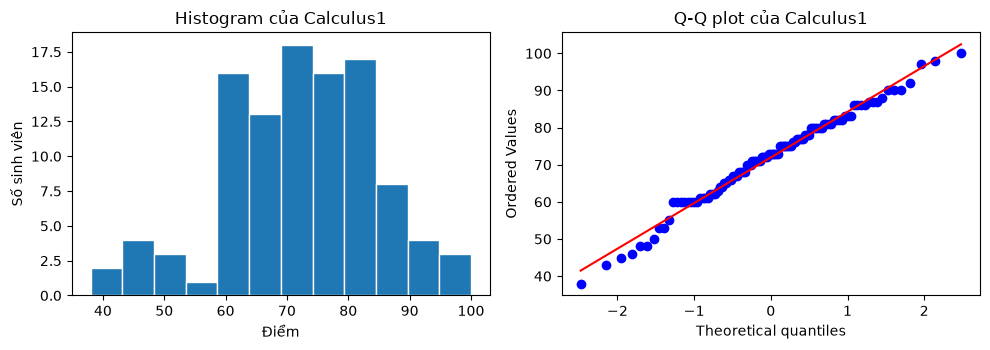

Shapiro-Wilk p = 0.3329  (p > 0.05: không bác bỏ giả thuyết chuẩn)


In [8]:
c1 = df['Calculus1']

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(c1, bins=12, edgecolor='white')
ax[0].set_title('Histogram của Calculus1'); ax[0].set_xlabel('Điểm'); ax[0].set_ylabel('Số sinh viên')
stats.probplot(c1, plot=ax[1]); ax[1].set_title('Q-Q plot của Calculus1')
plt.tight_layout(); plt.show()

print(f'Shapiro-Wilk p = {stats.shapiro(c1).pvalue:.4f}  (p > 0.05: không bác bỏ giả thuyết chuẩn)')

In [29]:
res_b = ci_var(c1, CONF)
show(res_b, 'Kết quả (b): CI 95% cho phương sai điểm Calculus1')
print(f"=> CI 95% cho σ²: ({res_b['lower']:.2f} ; {res_b['upper']:.2f})")
print(f"=> tương ứng CI 95% cho độ lệch chuẩn σ: ({res_b['sd_lower']:.2f} ; {res_b['sd_upper']:.2f}) điểm")
print(f"   (s² mẫu = {res_b['s2']:.2f} gần cận dưới hơn cận trên: khoảng KHÔNG đối xứng quanh s², nó kéo dài về phía trên)")

Kết quả (b): CI 95% cho phương sai điểm Calculus1


,giá trị
n,105.0000
s2,148.7678
chi_left,77.6722
chi_right,134.1112
lower,115.3658
upper,199.1942
sd_lower,10.7408
sd_upper,14.1136


=> CI 95% cho σ²: (115.37 ; 199.19)
=> tương ứng CI 95% cho độ lệch chuẩn σ: (10.74 ; 14.11) điểm
   (s² mẫu = 148.77 gần cận dưới hơn cận trên: khoảng KHÔNG đối xứng quanh s², nó kéo dài về phía trên)


**Nhận xét:** Điều kiện: Điểm Calculus1 không bác bỏ được tính chuẩn (Shapiro $p=0,333 > 0,05$), Q-Q plot cho thấy các điểm bám khá sát đường thẳng. Các môn khác vi phạm điều kiện chuẩn nên không được chọn. 
Kết quả: Với độ tin cậy 95%, phương sai điểm Calculus1 của tổng thể nằm trong (115,37; 199,19), tương đương độ lệch chuẩn khoảng (10,74; 14,11) điểm. 
Ý nghĩa: Điểm Calculus1 của sinh viên phân tán khá nhiều quanh trung bình, nghĩa là có sự chênh lệch rõ rệt về điểm số môn này giữa các sinh viên.

## 5. Câu (c): Khoảng tin cậy 95% cho tỷ lệ sinh viên nữ

**Công thức** (xấp xỉ chuẩn):
$$\hat p \;\pm\; z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}, \qquad \hat p=\frac{\text{số sinh viên nữ}}{n}$$

**Điều kiện áp dụng:**
1. Mẫu ngẫu nhiên, các quan sát độc lập.
2. $n\hat p \ge 5$ và $n(1-\hat p) \ge 5$ (đủ nhiều "thành công" và "thất bại" để xấp xỉ chuẩn hợp lệ).

In [9]:
n_c = len(df)
k_female = int((df['gender'] == 'female').sum())
p_hat = k_female / n_c

print(f'Số nữ = {k_female}, số nam = {n_c - k_female}, p̂ = {p_hat:.4f}')
print(f'Điều kiện: n·p̂ = {n_c * p_hat:.1f} ≥ 5 ? {n_c * p_hat >= 5}   |   n·(1−p̂) = {n_c * (1 - p_hat):.1f} ≥ 5 ? {n_c * (1 - p_hat) >= 5}')

res_c = ci_prop(k_female, n_c, CONF)
show(res_c, 'Kết quả (c): CI 95% cho tỷ lệ sinh viên nữ')
print(f"=> CI 95% cho p: ({res_c['lower']:.4f} ; {res_c['upper']:.4f})  tức ({100*res_c['lower']:.1f}% ; {100*res_c['upper']:.1f}%)")

Số nữ = 68, số nam = 37, p̂ = 0.6476
Điều kiện: n·p̂ = 68.0 ≥ 5 ? True   |   n·(1−p̂) = 37.0 ≥ 5 ? True
Kết quả (c): CI 95% cho tỷ lệ sinh viên nữ


,giá trị
n,105.0000
successes,68.0000
p_hat,0.6476
z,1.9600
se,0.0466
margin,0.0914
lower,0.5562
upper,0.7390


=> CI 95% cho p: (0.5562 ; 0.7390)  tức (55.6% ; 73.9%)


**Nhận xét:** Điều kiện: $n\hat{p} = 68$ và $n(1-\hat{p}) = 37$ đều $\ge 5$ nên xấp xỉ chuẩn hợp lệ. 
Kết quả: Với độ tin cậy 95%, tỷ lệ sinh viên nữ trong tổng thể nằm trong khoảng (55,6%; 73,9%). 
Lưu ý: Tỷ lệ này phản ánh cơ cấu giới tính của chương trình Toán đang xét (tổng thể sinh viên ngành này), trong đó sinh viên nữ chiếm đa số.

## 6. Câu (d): Khoảng tin cậy 95% cho hiệu kỳ vọng GPA giữa sinh viên nam và nữ

Gọi $\mu_1$ là GPA trung bình của nam, $\mu_2$ là GPA trung bình của nữ.

Hai công thức, chọn theo giả định về phương sai:

| | Giả sử $\sigma_1^2=\sigma_2^2$ (pooled) | Không giả sử (Welch) |
|---|---|---|
| Khoảng | $(\bar x_1-\bar x_2)\pm t_{n_1+n_2-2,\alpha/2}\; s_p\sqrt{\tfrac1{n_1}+\tfrac1{n_2}}$ | $(\bar x_1-\bar x_2)\pm t_{\nu,\alpha/2}\sqrt{\tfrac{s_1^2}{n_1}+\tfrac{s_2^2}{n_2}}$ |
| Với | $s_p^2=\dfrac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}$ | $\nu=\dfrac{\left(\tfrac{s_1^2}{n_1}+\tfrac{s_2^2}{n_2}\right)^2}{\tfrac{(s_1^2/n_1)^2}{n_1-1}+\tfrac{(s_2^2/n_2)^2}{n_2-1}}$ (không nguyên, không sao) |

**Điều kiện áp dụng:**
1. Hai mẫu độc lập với nhau.
2. Mỗi nhóm xấp xỉ chuẩn, hoặc cỡ mẫu mỗi nhóm đủ lớn ($\ge 30$) để dùng CLT.
3. Chọn pooled chỉ khi có cơ sở cho $\sigma_1^2=\sigma_2^2$; nếu không thì dùng Welch.

Nam : n = 37,  trung bình = 81.85,  độ lệch chuẩn = 7.16
Nữ  : n = 68,  trung bình = 83.56,  độ lệch chuẩn = 5.32


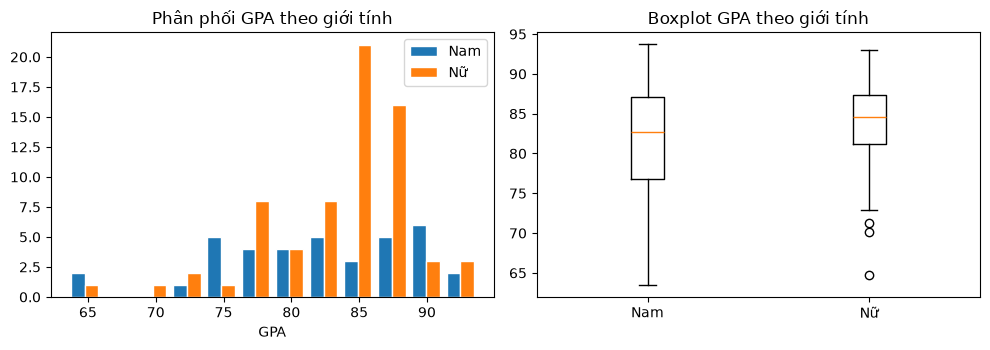


Kiểm định Levene (H0: hai phương sai bằng nhau): p = 0.0174
=> p nhỏ (< 0.05) nghĩa là có bằng chứng phương sai KHÁC nhau, nên dùng Welch.


In [10]:
male = df.loc[df['gender'] == 'male', 'GPA']
female = df.loc[df['gender'] == 'female', 'GPA']

print(f'Nam : n = {len(male)},  trung bình = {male.mean():.2f},  độ lệch chuẩn = {male.std(ddof=1):.2f}')
print(f'Nữ  : n = {len(female)},  trung bình = {female.mean():.2f},  độ lệch chuẩn = {female.std(ddof=1):.2f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist([male, female], bins=12, label=['Nam', 'Nữ'], edgecolor='white')
ax[0].set_title('Phân phối GPA theo giới tính'); ax[0].set_xlabel('GPA'); ax[0].legend()
ax[1].boxplot([male, female], tick_labels=['Nam', 'Nữ']); ax[1].set_title('Boxplot GPA theo giới tính')
plt.tight_layout(); plt.show()

lev = stats.levene(male, female)
print(f'\nKiểm định Levene (H0: hai phương sai bằng nhau): p = {lev.pvalue:.4f}')
print('=> p nhỏ (< 0.05) nghĩa là có bằng chứng phương sai KHÁC nhau, nên dùng Welch.')

In [11]:
res_d = ci_diff_welch(male, female, CONF)
show(res_d, 'Kết quả (d): CI 95% cho μ_nam − μ_nữ (Welch)')
print(f"=> CI 95% cho μ1 − μ2: ({res_d['lower']:.2f} ; {res_d['upper']:.2f})")
print('   Khoảng', 'CHỨA' if res_d['lower'] <= 0 <= res_d['upper'] else 'KHÔNG chứa', 'giá trị 0')

res_d_pooled = ci_diff_pooled(male, female, CONF)
print(f"\n(Tham khảo) CI theo pooled: ({res_d_pooled['lower']:.2f} ; {res_d_pooled['upper']:.2f}),  bậc tự do = {res_d_pooled['df']:.0f}")

Kết quả (d): CI 95% cho μ_nam − μ_nữ (Welch)


,giá trị
n1,37.0000
n2,68.0000
mean1,81.8522
mean2,83.5582
diff,-1.7061
se,1.3418
df,58.1054
t_crit,2.0016
margin,2.6857
lower,-4.3918


=> CI 95% cho μ1 − μ2: (-4.39 ; 0.98)
   Khoảng CHỨA giá trị 0

(Tham khảo) CI theo pooled: (-4.15 ; 0.74),  bậc tự do = 103


**Nhận xét:** Điều kiện: Hai nhóm độc lập; mỗi nhóm $n_{nam} = 37$ và $n_{nữ} = 68$ (đều $\ge 30$) nên dùng CLT dù GPA lệch; kiểm định Levene cho $p = 0,0174 < 0,05$ nên chọn công thức Welch. 
Kết quả: Với độ tin cậy 95%, GPA trung bình của nam so với nữ chênh lệch trong khoảng (-4,39; 0,98) điểm. 
Kết luận: Vì khoảng tin cậy chứa 0 nên chưa đủ bằng chứng về sự khác biệt giữa hai nhóm trong mẫu này. Thận trọng: đây là dữ liệu quan sát, không kết luận giới tính là nguyên nhân của chênh lệch GPA.